# Programmed I/Q, ten-nanosecond transitions and a dynamical LINC coupler

The effective JC model is not a device-level certificate during a fast pump
change. This notebook propagates an explicit, driven **cosine LINC Hamiltonian**
with a quantum coupler ladder, the cavity and a perfect two-level qubit.
The input waveform is the actual SDK-packed signed I/Q followed by the documented
RFDC interpolation, rather than an instantaneous change of an effective coupling.

The user's 6.8 GHz operating frequency and approximately 4 GHz tuning span
constrain the circuit. Other parameters are labelled assumptions. The simulated
analog reconstruction is ideal; a measured flux-line transfer function and
device asymmetries have not been supplied. The results below are predictions
for the stated circuit, not measured fidelities for the device.

We compare abrupt steps, ten-nanosecond phase/IQ ramps, a 5 ns down/5 ns up
transition, and a simpler **constant-pump** CD motif. Existing Gaussian and CD
notebooks remain [here](../conditional_gaussian_gates.ipynb) and
[here](../fast_conditional_displacement.ipynb), with all figures saved.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS

import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import cd_trains as cd
import hardware_check as hw
from coupler_phase_model import Circuit,operators,boundary_words,microscopic,effective_score
from calibrate_coupler import floquet_pair
from verify_scaled_cd import rule
from acadia.sample_arithmetic import sample_to_complex
ROOT=PROJECT_ROOT;DATA=ROOT/'runs/coupler';FIG=DATA/'figures';FIG.mkdir(exist_ok=True)
base=Circuit();inferred=base.parameters()
display(pd.DataFrame([dict(quantity=k,value=v) for k,v in inferred.items()]))

,quantity,value
0,EL_GHz,57.800000
1,EJ_GHz,16.248077
2,ratio_2EJ_EL,0.562217
3,lambda_c,0.242536
4,lambda_q,0.013414
5,lambda_a,0.006871
6,flux_at_DAC_0045,0.289588
7,flux_per_DAC,6.435285
8,inferred_fmin_GHz,4.499231
9,inferred_fmax_GHz,8.499231


## What the measured frequencies determine

Assume that 6.8 GHz is the LINC frequency at its linear bias point. With
$\rho=2E_J/E_L$, the ideal static frequency is

$$f(\phi)=f_0\sqrt{1+\rho\cos\phi},\qquad
\rho=d\sqrt{1-d^2/4},\quad d=\frac{f_{\max}-f_{\min}}{f_0}.$$

The two numbers imply $\rho=0.562217$ and
$(E_C/h)(E_L/h)=5.78\;\mathrm{GHz}^2$, with extrema about 4.499 and 8.499 GHz.
They do **not** determine $E_C$ separately, the mode participations, array size,
junction imbalance or flux delivered per DAC volt. We use $E_C/h=100$ MHz,
one LINC loop, and illustrative linear couplings of 120/50 MHz from the paper.
These assumptions can be changed in `Circuit`; they are not inferred measurements.

Mode participations are first-order weak-mixing estimates
$\lambda_{q,a}\simeq\lambda_c g_{qc,ac}/(f_c-f_{q,a})$; the two supplied
frequencies do not determine an exact static circuit-mode fit.

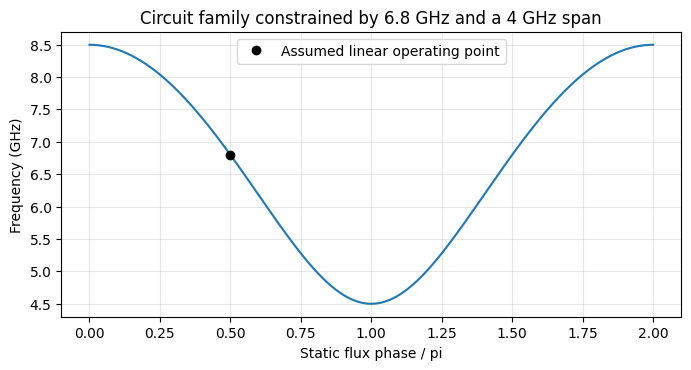

,EC_GHz,EL_GHz,EJ_GHz,lambda_c
0,0.080,72.250000,20.310096,0.216930
1,0.100,57.800000,16.248077,0.242536
2,0.126,45.873016,12.895299,0.272246


In [2]:
phi=np.linspace(0,2*np.pi,601)
frequency=base.f_coupler_GHz*np.sqrt(1+inferred['ratio_2EJ_EL']*np.cos(phi))
fig,ax=plt.subplots(figsize=(8,3.7))
ax.plot(phi/np.pi,frequency);ax.plot([.5],[6.8],'ko',label='Assumed linear operating point')
ax.set(xlabel='Static flux phase / pi',ylabel='Frequency (GHz)',title='Circuit family constrained by 6.8 GHz and a 4 GHz span')
ax.grid(alpha=.3);ax.legend();fig.savefig(FIG/'static_frequency.png',dpi=160);plt.show()
rows=[]
for EC in [.08,.10,.126]:
    from dataclasses import replace
    p=replace(base,EC_GHz=EC).parameters()
    rows.append(dict(EC_GHz=EC,EL_GHz=p['EL_GHz'],EJ_GHz=p['EJ_GHz'],lambda_c=p['lambda_c']))
display(pd.DataFrame(rows))

## Hamiltonian and the phase convention

At the linear point, the [LINC paper](https://arxiv.org/html/2501.18025v3)
gives $H_c=4E_C n_c^2+E_L\theta_c^2/2+2E_J\sin\Phi(t)\cos\theta_c$.
In a weakly hybridized normal-mode basis we propagate

$$
H(t)=H_0+2M^2E_J\sin\Phi(t)\,\mathcal P_2
\cos\!\left(\frac{\Theta}{M}\right)\mathcal P_2+H_{q,\mathrm{RF}}(t),
\qquad \Theta=\lambda_c(c+c^\dagger)+\lambda_a(a+a^\dagger)+\lambda_q(b+b^\dagger).
$$

$M$ is the number of arrayed LINC loops; $\mathcal P_2$ keeps qubit g/e.
The complete cosine and sine drive are retained. The coupler is not eliminated,
and pump counter-rotating/higher-order processes are not replaced by JC.
The two-level qubit restriction and assumed normal-mode participations are
explicit model choices. Static chi is absent; driven shifts are still generated.

The programmed pump enters as

$$\Phi(t)=-K_\Phi\operatorname{Re}\!\left[z_{p,\mathrm{RFDC}}(t)e^{i\omega_p t}\right].$$

The supplied CD model uses qubit I/Q multiplying the lowering operator.
Therefore physical qubit DAC phase is **minus** its Hamiltonian-axis phase;
pump DAC phase has the same sign. This sign is applied before SDK packing.
The actual signed words are then interpolated with the documented RFDC FIRs.
Between 6.4 GS/s output points the analog envelope is linearly reconstructed.
This specifies an ideal analog flux path; undocumented converter rounding,
analog filtering, imbalance and dissipative heating are not claimed simulated.

## Why a ten-nanosecond ramp helps but is not a theorem

A time-dependent Hamiltonian and its quantum state remain well-defined during
the ramp. What can fail is a fixed-period or instantaneous effective-Hamiltonian
approximation. A parameter-dependent dressed basis has

$$H_{\rm dressed}=R^\dagger H R-iR^\dagger\dot R.$$

Direct laboratory-frame propagation includes this basis-motion effect without
adding a second derivative correction by hand. Ten nanoseconds is about four
pump cycles here, but relevant avoided-crossing gaps and matrix elements also
set the required ramp speed. A finite closed system does not relax into a
unique Floquet steady state; preparation of a Floquet mode and an open-system
long-time steady state are different questions.

The four waveforms below have the same 60 ns command window. The central
transition is 10 ns, with identical 5 ns outer ramps. `phase` follows the
shortest angle at constant magnitude; `cartesian` uses a smooth straight line
in complex I/Q; `zero` ramps down for 5 ns and back up for 5 ns, changing phase
only at zero. The plotted RFDC delay is removed for display only.

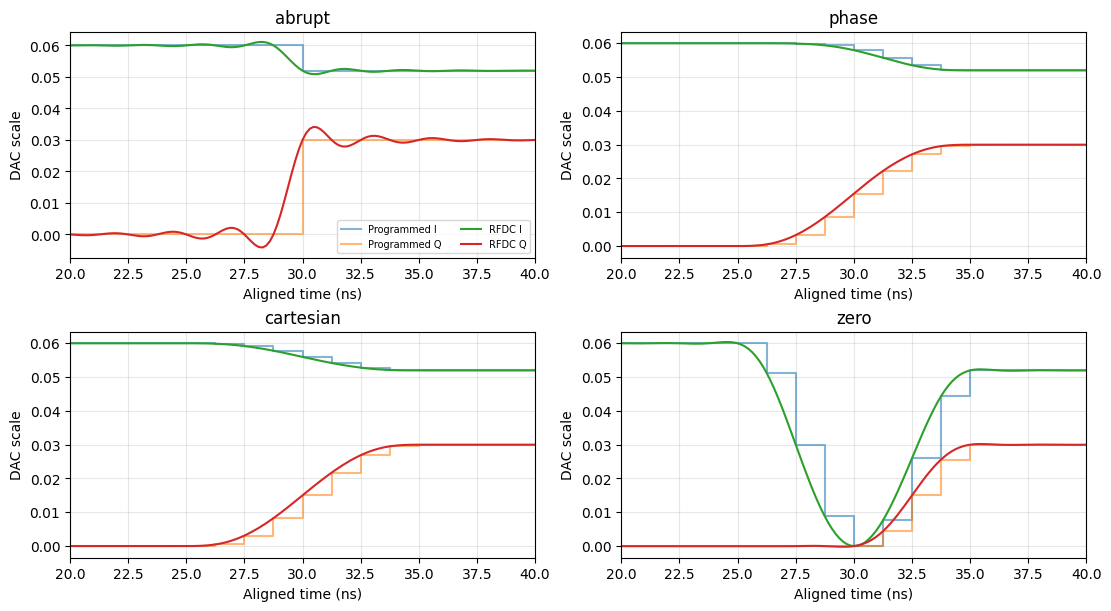

In [3]:
shapes=['abrupt','phase','cartesian','zero']
fig,axes=plt.subplots(2,2,figsize=(11,6),constrained_layout=True)
for ax,shape in zip(axes.ravel(),shapes):
    words=boundary_words(np.pi/6,shape)
    programmed=sample_to_complex(words['sideband']);played=hw.rfdc_interpolate(programmed)
    t=np.arange(len(programmed))*cd.DT*1000
    fine=np.arange(len(played))*cd.DT*1000/8-22.65625
    ax.step(t,programmed.real,where='post',label='Programmed I',alpha=.55)
    ax.step(t,programmed.imag,where='post',label='Programmed Q',alpha=.55)
    ax.plot(fine,played.real,label='RFDC I');ax.plot(fine,played.imag,label='RFDC Q')
    ax.set(title=shape,xlim=(20,40),xlabel='Aligned time (ns)',ylabel='DAC scale');ax.grid(alpha=.3)
axes[0,0].legend(fontsize=7,ncol=2);fig.savefig(FIG/'transition_IQ.png',dpi=160);plt.show()

## What the optimizers found: one motif and a scaling rule

The original library used L-BFGS-B on a cell-matrix surrogate, followed by actual
playback verification. The reusable family instead fits a small shared pattern
directly through SDK+RFDC replay at beta=0.2, 0.4, 1 and 2.
For the eight-pulse rotary echo, four first-half qubit axes determine the
opposed reversed second half; pump phases are mirrored. The general fit has
nine variables (four qubit axes, four pump phases, one common pump scale).
The **constant-pump** fit has only five (four qubit axes and one pump scale).
All qubit rotation angles remain pi with 30 ns envelopes. Phase specifies the
axis; it does not change the rotation to pi/N.

The objective is mean infidelity plus maximum infidelity across the four
training strengths. Seeds are the standard echo and small reproducible phase
perturbations. After fitting, phases are rounded to 0.1 degree and pump gain
to six decimals; those rounded values are independently verified. No individual
waveform sample is optimized. The zero-amplitude transition failed to reach
99% across the same family even after refinement and is a diagnostic.

The old CD `qubit only` grid fixed the pump at zero, while real CD naturally
uses minus pi/2. It does not prove pump-phase changes are essential. The fair
constant-pump comparison below succeeds and avoids rapid pump-phase changes.

For $b=|\beta|$, take $M=\lceil b/0.4\rceil$ up to beta=2; above that take the
larger of this and $\lceil5(b/2)^2\rceil$. Set signed pump multiplier
$s=\beta/(0.4M)$ and repeat the eight rows M times. Negative s adds pi to the
pump phase. Beta zero skips the gate. Only one outer ramp at each end is added.
This rule is tested at twenty signed strengths up to |beta|=4; it is not a
proof for every real beta or for arbitrarily large gates.

constant rounded eight-row physical DAC motif; pi envelopes30ns


,pulse,qubit_DAC_deg,pump_DAC_deg
0,1,0.3,270.0
1,2,2.4,270.0
2,3,181.6,270.0
3,4,175.6,270.0
4,5,355.6,270.0
5,6,1.6,270.0
6,7,182.4,270.0
7,8,180.3,270.0


cartesian rounded eight-row physical DAC motif; pi envelopes30ns


,pulse,qubit_DAC_deg,pump_DAC_deg
0,1,357.6,289.5
1,2,357.6,285.0
2,3,180.1,253.2
3,4,178.7,258.0
4,5,358.7,258.0
5,6,0.1,253.2
6,7,177.6,285.0
7,8,177.6,289.5


,kind,beta,repeats,gain,command_us,RFDC_window_us,fidelity,fidelity_nmax8
0,constant,0.050,1,0.125000,0.25,0.294219,0.999968,0.999974
1,constant,-0.500,2,-0.625000,0.49,0.534219,0.999346,0.999438
2,constant,0.100,1,0.250000,0.25,0.294219,0.999888,0.999907
3,constant,0.125,1,0.312500,0.25,0.294219,0.999826,0.999856
4,constant,0.200,1,0.500000,0.25,0.294219,0.999573,0.999644
5,constant,-1.000,3,-0.833333,0.73,0.774219,0.998642,0.998890
6,constant,0.300,1,0.750000,0.25,0.294219,0.999083,0.999248
7,constant,0.400,1,1.000000,0.25,0.294219,0.998219,0.998577
8,constant,-2.000,5,-1.000000,1.21,1.254219,0.992715,0.994846
9,constant,0.500,2,0.625000,0.49,0.534219,0.999346,0.999438


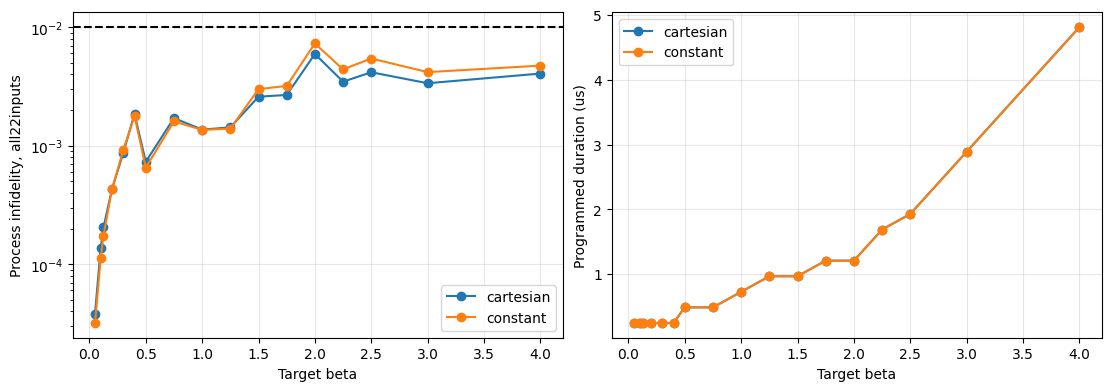

Independent effective-model check: 40 gates, 880 input columns, 174592 complex amplitudes.


In [4]:
families=json.load(open(ROOT/'runs/transition_families/manifest.json'))
assert families['gates']==40 and families['columns']==880
family_table=pd.DataFrame(families['results'])
for kind in ['constant','cartesian']:
    row=family_table[(family_table.kind==kind)&np.isclose(family_table.beta,1)].iloc[0]
    p=np.asarray(row.parameters);qh=np.array([0,0,np.pi,np.pi])+p[:4]
    q=np.r_[qh,qh[::-1]+np.pi];ph=-np.pi/2+p[4:8];pump=np.r_[ph,ph[::-1]]
    print(kind,'rounded eight-row physical DAC motif; pi envelopes30ns')
    display(pd.DataFrame(dict(pulse=np.arange(1,9),qubit_DAC_deg=np.degrees(-q)%360,pump_DAC_deg=np.degrees(pump)%360)))
display(family_table[['kind','beta','repeats','gain','command_us','RFDC_window_us','fidelity','fidelity_nmax8']])
fig,axes=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
for kind,group in family_table[family_table.beta>0].groupby('kind'):
    group=group.sort_values('beta');axes[0].semilogy(group.beta,1-group.fidelity,'o-',label=kind)
    axes[1].plot(group.beta,group.command_us,'o-',label=kind)
axes[0].axhline(.01,color='k',ls='--');axes[0].set(xlabel='Target beta',ylabel='Process infidelity, all22inputs')
axes[1].set(xlabel='Target beta',ylabel='Programmed duration (us)')
for ax in axes:ax.grid(alpha=.3);ax.legend()
fig.savefig(FIG/'effective_scaling.png',dpi=160);plt.show()
print('Independent effective-model check:',families['gates'],'gates,',families['columns'],
      'input columns,',families['independent_amplitudes'],'complex amplitudes.')

## Numerical checks and speed

The fixed circuit operators are precomputed once. Analytic Laguerre matrix
elements project the infinite-oscillator cosine into each Fock space; taking
cosine after truncating the position matrix can converge much more slowly.
Tiny discarded sparse entries have an explicit integrated norm bound.

The C++ propagator uses commutator-free Magnus steps with two exponentials.
Chebyshev/Bessel actions use a certified spectral-radius tail bound; the
independent Taylor implementation remains available. An adaptive DOP853 solver
and a separate large-matrix cosine check the implementation. Norm preservation
alone is not treated as evidence of accuracy. Floquet one-period maps cheaply
calibrate constant-drive rates instead of fitting many full swap traces.
The full cavity/qubit/coupler state is retained; nothing is projected back and
renormalized before calculating fidelity.

,timestep_ns,amplitudes,max_difference
0,0.0100,96,3.898026e-06
1,0.0050,96,2.454486e-07
2,0.0025,96,5.519530e-08


,shape,max_coupler_excitation,cavity_levels,coupler_levels,last_column_change
0,abrupt,0.003503,20,10,3.483086e-07
1,phase,0.003430,20,10,3.207696e-07
2,cartesian,0.002763,20,10,2.490011e-07
3,zero,0.000018,20,10,9.575179e-08


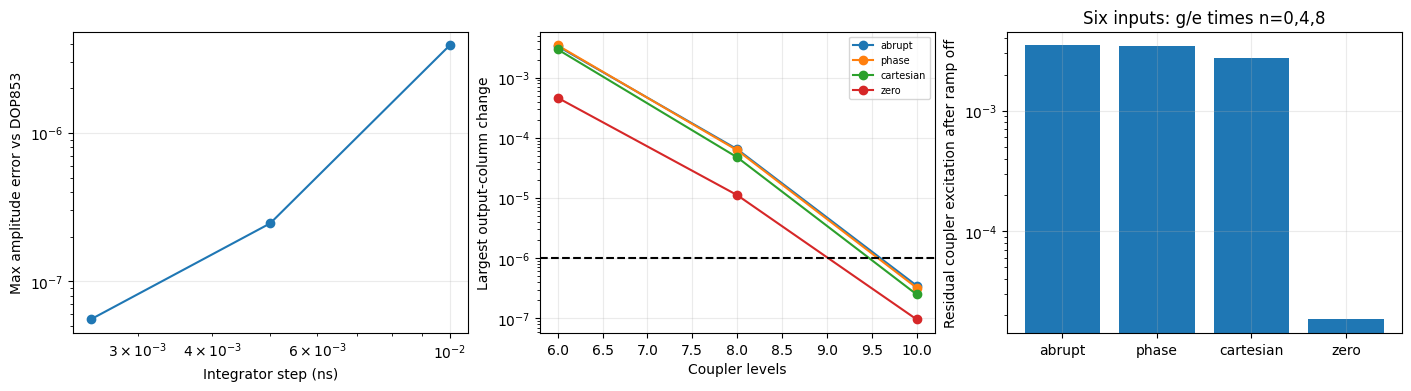

Boundary comparisons: 96 propagated columns.


In [5]:
independent=json.load(open(DATA/'independent_integrator.json'))
checks=pd.DataFrame(independent['checks']);display(checks)
boundaries=json.load(open(DATA/'boundary_summary.json'))
assert len(boundaries)==4 and all(r['converged_1e6'] for r in boundaries)
display(pd.DataFrame([dict(shape=r['shape'],max_coupler_excitation=r['max_final_coupler_excitation'],
                           cavity_levels=r['cavity_levels'],coupler_levels=r['coupler_levels'],
                           last_column_change=r['convergence_history'][-1]['column_change']) for r in boundaries]))
fig,axes=plt.subplots(1,3,figsize=(14,3.8),constrained_layout=True)
axes[0].loglog(checks.timestep_ns,checks.max_difference,'o-')
axes[0].set(xlabel='Integrator step (ns)',ylabel='Max amplitude error vs DOP853')
for r in boundaries:
    history=r['convergence_history'];axes[1].semilogy([h['coupler_levels'] for h in history[1:]],
                              [h['column_change'] for h in history[1:]],'o-',label=r['shape'])
axes[1].axhline(1e-6,ls='--',color='k');axes[1].set(xlabel='Coupler levels',ylabel='Largest output-column change')
axes[1].legend(fontsize=7)
axes[2].bar([r['shape'] for r in boundaries],[r['max_final_coupler_excitation'] for r in boundaries])
axes[2].set(yscale='log',ylabel='Residual coupler excitation after ramp off',title='Six inputs: g/e times n=0,4,8')
for ax in axes:ax.grid(alpha=.25)
fig.savefig(FIG/'coupler_convergence.png',dpi=160);plt.show()
print('Boundary comparisons:',sum(len(r['convergence_history'])*r['columns'] for r in boundaries),'propagated columns.')

## Observable calibrations, followed by an all-input gate test

A weak-drive formula is not a measured strong-drive coupling. We first match
the assumed circuit's exact one-period map to the measured 600 ns swap and the
driven carrier references. This calibrates model gain and resonances without
using a CD target. At stronger pump amplitude, driven frequency shifts and
nonlinear gain remain; calibrating only at 600 ns was insufficient for the
new CD and did not produce a 99% gate.

We next calibrate the conditional displacement strength and direction from
**only two vacuum inputs**, |+x,0> and |-x,0>, using their mean cavity amplitude.
No gate trace or Fock n>=1 output enters this strength calibration. It does
not fix the relative Fock-state phases: the raw scores below remain below 99%.

We then calibrate **two common frame angles** from fixed observable references:
the difference of cavity first moments for $|+x\rangle|\pm0.5\rangle$ fixes
the cavity frame, and their mean qubit coherence fixes the qubit frame.
The code reconstructs these normalized, n<=8 truncated coherent inputs by
linearity from the cached output columns. This is a calibration on known
observables, not a statistically held-out data set; neither the target matrix
nor gate fidelity is an argument to `observer_frames`. No per-input phases
are fitted. The norm of the omitted true-coherent-state tail is below
$2.9\times10^{-6}$.

The subsequent gate calculation uses every g/e times n=0…8 input, including
relative phases, against the **fixed** target CD(0.4). It includes the declared
common frame corrections. We show the uncompensated score alongside it.

The small frequency corrections are explicit I/Q phase advances in the
exported arrays at the original NCOs. Apply or explicitly track the listed
total $R_z(\zeta)=e^{-i\zeta\sigma_z/2}$ and
$R_c(\varphi)=e^{-i\varphi a^\dagger a}$ updates after the train. Those
rotations are part of the reported corrected gate. The metric also includes
a target coupler vacuum, so residual coupler excitation reduces fidelity.

constant vacuum-only strength calibration:


,iteration,peak_DAC_scale,conditional_beta_real,conditional_beta_imag,unconditional_alpha_real,unconditional_alpha_imag,columns,elapsed_seconds
0,0,0.055231,0.423158,-0.016907,0.000114,0.001201,2,55.129489
1,1,0.052167,0.395077,0.001309,0.000051,0.000978,2,55.392848
2,2,0.052817,0.401176,-0.000243,0.000057,0.001022,2,55.466429


cartesian vacuum-only strength calibration:


,iteration,peak_DAC_scale,conditional_beta_real,conditional_beta_imag,unconditional_alpha_real,unconditional_alpha_imag,columns,elapsed_seconds
0,0,0.056777,0.422546,-0.020123,0.000647,0.001152,2,55.190135
1,1,0.053687,0.394976,0.001421,0.000478,0.000961,2,55.413961
2,2,0.054370,0.401134,-0.000334,0.000505,0.001004,2,55.492134


,kind,before_observable_frames_F,with_observable_frames_F,corrected_worst_basis_F,coupler_excitation,total_qubit_Rz_rad,total_cavity_R_rad
0,constant,0.977180,0.993644,0.989308,0.000161,-0.062626,0.011521
1,cartesian,0.973966,0.992851,0.988052,0.000285,-0.092120,0.023205


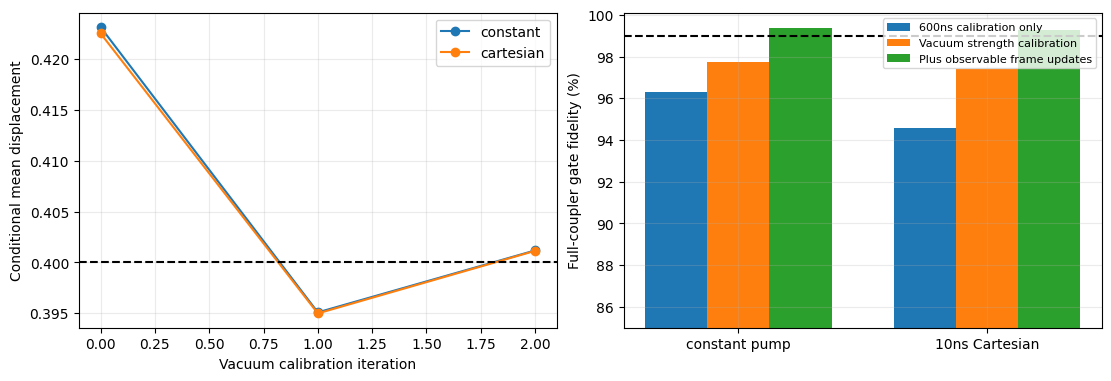

In [6]:
before=[];after=[];calibrations={}
for kind in ['constant','cartesian']:
    before.append(json.load(open(DATA/f'full_{kind}_a20_c8_dt0.005_calibrated.json')))
    after.append(json.load(open(DATA/f'programmed_{kind}_a20_c8_dt0.005.json')))
    calibrations[kind]=json.load(open(DATA/f'vacuum_calibrated_{kind}.json'))
    print(kind,'vacuum-only strength calibration:')
    display(pd.DataFrame(calibrations[kind]['vacuum_calibration_history']))
display(pd.DataFrame([dict(kind=r['kind'],before_observable_frames_F=r['coherent_gate_fidelity'],
                           with_observable_frames_F=r['observer_frame_calibration']['coherent_gate_fidelity'],
                           corrected_worst_basis_F=r['observer_frame_calibration']['worst_basis_fidelity'],
                           coupler_excitation=r['max_final_coupler_excitation'],
                           total_qubit_Rz_rad=r['total_final_qubit_Rz_rad'],
                           total_cavity_R_rad=r['total_final_cavity_R_rad']) for r in after]))
fig,axes=plt.subplots(1,2,figsize=(11,3.7),constrained_layout=True)
for kind,record in calibrations.items():
    history=record['vacuum_calibration_history'];axes[0].plot([x['iteration'] for x in history],
                 [x['conditional_beta_real'] for x in history],'o-',label=kind)
axes[0].axhline(.4,ls='--',color='k');axes[0].set(xlabel='Vacuum calibration iteration',ylabel='Conditional mean displacement')
axes[0].legend()
x=np.arange(2)
axes[1].bar(x-.25,[100*r['coherent_gate_fidelity'] for r in before],.25,label='600ns calibration only')
axes[1].bar(x,[100*r['coherent_gate_fidelity'] for r in after],.25,label='Vacuum strength calibration')
axes[1].bar(x+.25,[100*r['observer_frame_calibration']['coherent_gate_fidelity'] for r in after],.25,
            label='Plus observable frame updates')
axes[1].set(xticks=x,xticklabels=['constant pump','10ns Cartesian'],ylabel='Full-coupler gate fidelity (%)',ylim=(85,100.1))
axes[1].axhline(99,ls='--',color='k');axes[1].legend(fontsize=8)
for ax in axes:ax.grid(alpha=.25)
fig.savefig(FIG/'microscopic_calibration.png',dpi=160);plt.show()

### Complete microscopic pulse prescription

The following table and waveforms are for the **microscopically calibrated**
programs, which differ from the rounded effective-model motifs above. All
qubit pulses remain 30 ns Hann pi pulses. The table gives physical base phases;
add $2\pi\delta f_q(t+\tau_g)$ to the qubit phase and
$2\pi\delta f_p(t+\tau_g)$ to the pump phase, with $t$ in ns, detunings in GHz
and the known RFDC delay $\tau_g=22.65625$ ns. The constant family has a
constant base pump phase plus this slow chirp; the Cartesian family also
has the stated 10 ns transitions. The exact packed words, including these
chirps, are the authoritative playback prescription.

The last plot column shows the flux phase delivered by the modeled ideal
analog path near an internal boundary, including its continuous pump carrier.
It makes clear that a baseband phase interpolation modifies a rapidly
oscillating flux drive, rather than directly changing a JC coupling parameter.

constant qubit detune GHz -7.585314776736851e-05 pump detune GHz 3.9107753325495764e-05 pump plateau scale 0.052816973133076955


,pulse,start_ns,duration_ns,qubit_DAC_base_deg,pump_DAC_base_deg
0,1,5,30,0.269204,268.407424
1,2,35,30,2.449050,268.407424
2,3,65,30,181.618336,268.407424
3,4,95,30,175.648176,268.407424
4,5,125,30,355.648176,268.407424
5,6,155,30,1.618336,268.407424
6,7,185,30,182.449050,268.407424
7,8,215,30,180.269204,268.407424


cartesian qubit detune GHz -9.27660117850948e-05 pump detune GHz 4.752816294573137e-05 pump plateau scale 0.0543695264177492


,pulse,start_ns,duration_ns,qubit_DAC_base_deg,pump_DAC_base_deg
0,1,5,30,357.6,287.511662
1,2,35,30,357.6,283.011662
2,3,65,30,180.1,251.211662
3,4,95,30,178.7,256.011662
4,5,125,30,358.7,256.011662
5,6,155,30,0.1,251.211662
6,7,185,30,177.6,283.011662
7,8,215,30,177.6,287.511662


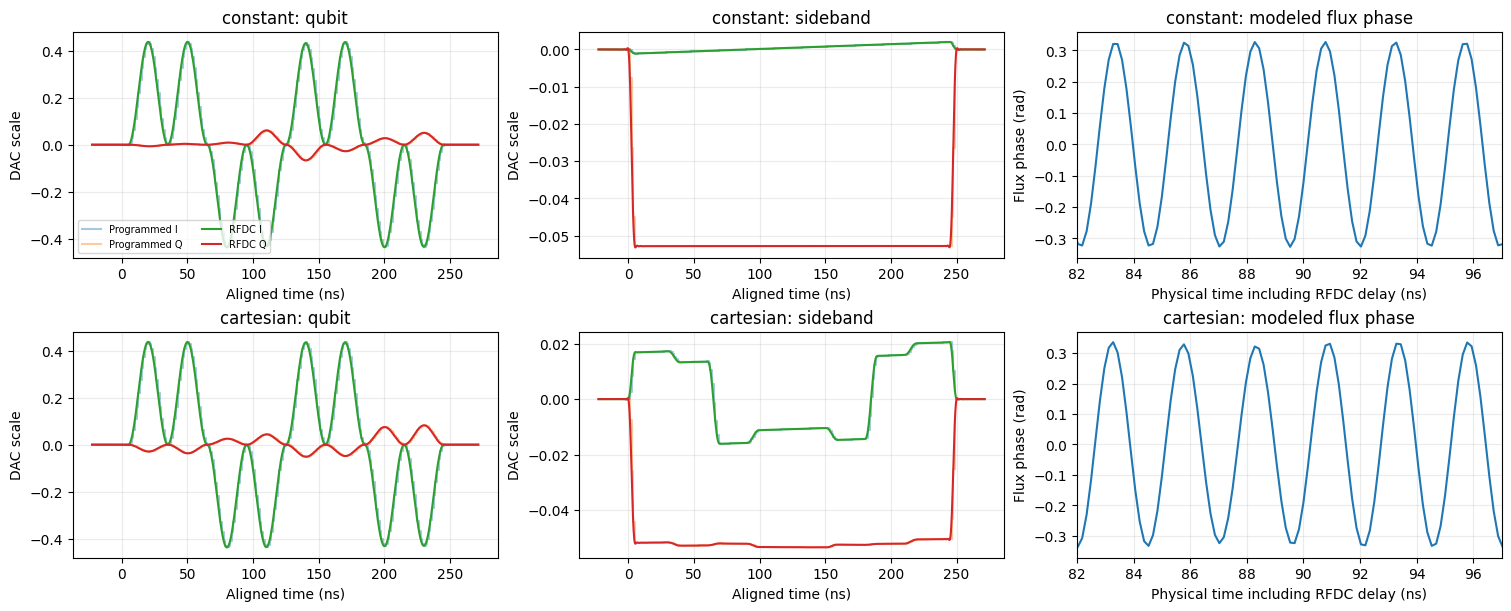

Exact microscopic words reconstructed and checked:2gates,2SHA256matches,16pulse rows exported.


In [7]:
from calibrate_programmed_family import programmed_words
fig,axes=plt.subplots(2,3,figsize=(15,6),constrained_layout=True)
for row,kind in zip(axes,['constant','cartesian']):
    record=calibrations[kind];p=np.asarray(record['parameters'])
    words=programmed_words(record)
    checked=next(r for r in after if r['kind']==kind)
    digest=hashlib.sha256(words['qubit'].tobytes()+words['sideband'].tobytes()).hexdigest()
    assert digest==checked['word_sha256']
    first=np.array([0,0,np.pi,np.pi])+p[:4]
    qbase=-np.r_[first,first[::-1]+np.pi]
    ph=-np.pi/2+p[4:8];pbase=np.r_[ph,ph[::-1]]+record['pump_phase_correction_rad']
    table=pd.DataFrame(dict(pulse=np.arange(1,9),start_ns=5+30*np.arange(8),duration_ns=30,
                  qubit_DAC_base_deg=np.degrees(qbase)%360,pump_DAC_base_deg=np.degrees(pbase)%360))
    table.to_csv(DATA/f'programmed_{kind}_sequence.csv',index=False)
    print(kind,'qubit detune GHz',record['qubit_IQ_detune_GHz'],
          'pump detune GHz',record['pump_IQ_detune_GHz'],'pump plateau scale',.09*p[8])
    display(table)
    for ax,key in zip(row[:2],['qubit','sideband']):
        programmed=sample_to_complex(words[key]);rf=hw.rfdc_interpolate(programmed)
        ts=np.arange(len(programmed))*1.25;tr=np.arange(len(rf))*.15625
        ax.step(ts,programmed.real,where='post',alpha=.4,label='Programmed I')
        ax.step(ts,programmed.imag,where='post',alpha=.4,label='Programmed Q')
        ax.plot(tr-22.65625,rf.real,label='RFDC I');ax.plot(tr-22.65625,rf.imag,label='RFDC Q')
        ax.set(title=kind+': '+key,xlabel='Aligned time (ns)',ylabel='DAC scale')
    pump=hw.rfdc_interpolate(sample_to_complex(words['sideband']))
    tr=np.arange(len(pump))*.15625
    circuit=Circuit(**record['reference_circuit']);parameters=circuit.parameters()
    flux=-parameters['flux_per_DAC']*np.real(pump*np.exp(2j*np.pi*circuit.pump_drive_GHz*tr))
    row[2].plot(tr,flux)
    row[2].set(xlim=(82,97),title=kind+': modeled flux phase',xlabel='Physical time including RFDC delay (ns)',ylabel='Flux phase (rad)')
    for ax in row:ax.grid(alpha=.25)
axes[0,0].legend(fontsize=7,ncol=2)
fig.savefig(FIG/'programmed_CD_IQ_and_flux.png',dpi=160);plt.show()
print('Exact microscopic words reconstructed and checked:2gates,2SHA256matches,16pulse rows exported.')

## What the programmed waveform does to the coupler

The following figures use the saved full-Hamiltonian output columns, not an
effective JC replacement. These are model predictions conditional on the
stated circuit and ideal analog reconstruction. Coherent residual excitation
is not a thermal population or a dissipative heating-rate prediction. Neither
a cold coupler nor a correct mean displacement alone guarantees a correct gate.

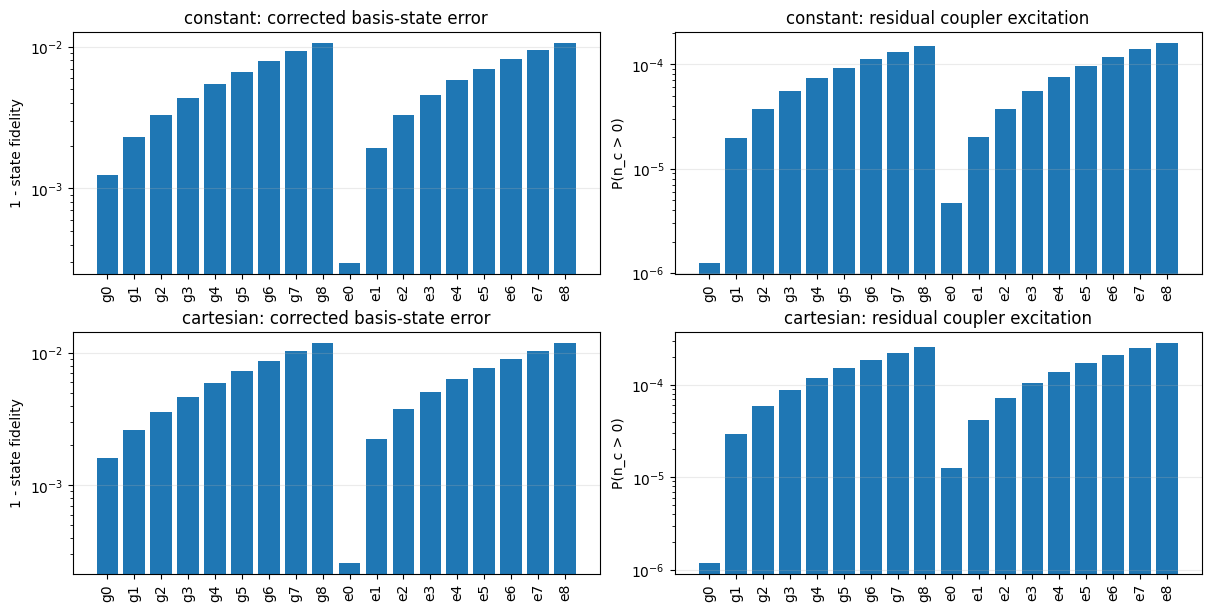

Full-model checks: 2 gates; 36 input columns; 11520 complex amplitudes.


,kind,check,cavity_levels,coupler_levels,timestep_ns,compared_input_columns,maximum_output_column_change
0,constant,cutoff,24,10,0.0050,2,1.955452e-07
1,constant,timestep,20,8,0.0025,2,1.469582e-07
2,cartesian,cutoff,24,10,0.0050,2,2.247918e-07
3,cartesian,timestep,20,8,0.0025,2,1.238511e-07


Additional numerical checks: 4 comparisons; 8 input columns; 3200 complex amplitudes.


In [8]:
fig,axes=plt.subplots(2,2,figsize=(12,6),constrained_layout=True)
for row,kind in zip(axes,['constant','cartesian']):
    data=np.load(DATA/f'programmed_{kind}_a20_c8_dt0.005_frame_corrected_columns.npz')
    output,desired=data['output'],data['target']
    overlaps=np.sum(desired.conj()*output,axis=0)
    tensor=output.reshape(20,8,2,18)
    excitation=np.sum(abs(tensor[:,1:])**2,axis=(0,1,2))
    row[0].bar(np.arange(18),1-abs(overlaps)**2)
    row[0].set(yscale='log',title=kind+': corrected basis-state error',ylabel='1 - state fidelity')
    row[1].bar(np.arange(18),np.maximum(excitation,1e-18))
    row[1].set(yscale='log',title=kind+': residual coupler excitation',ylabel='P(n_c > 0)')
    for ax in row:
        ax.set_xticks(range(18),[f'g{n}' for n in range(9)]+[f'e{n}' for n in range(9)],rotation=90)
        ax.grid(alpha=.25,axis='y')
fig.savefig(FIG/'microscopic_per_input.png',dpi=160);plt.show()
print('Full-model checks:',len(after),'gates;',sum(r['columns'] for r in after),'input columns;',
      sum(r['complex_amplitudes'] for r in after),'complex amplitudes.')
convergence=json.load(open(DATA/'programmed_convergence.json'))
assert len(convergence)==4 and sum(r['compared_input_columns'] for r in convergence)==8
assert max(r['maximum_output_column_change'] for r in convergence)<1e-5
display(pd.DataFrame([{key:r[key] for key in ['kind','check','cavity_levels','coupler_levels',
                         'timestep_ns','compared_input_columns','maximum_output_column_change']} for r in convergence]))
print('Additional numerical checks:',len(convergence),'comparisons;',
      sum(r['compared_input_columns'] for r in convergence),'input columns;',
      sum(r['compared_amplitudes'] for r in convergence),'complex amplitudes.')

## Fresh microscopic replay and limits of the conclusion

The next cell repeats a short actual-I/Q transition directly with the cosine
Hamiltonian and checks its two residual-excitation probabilities against the
larger-cutoff calculation. It also recomputes a one-period reference map.
The long full-gate calculations can be rerun with `verify_programmed_family.py`;
their source, assumptions, words and output columns are saved beside the figures.
All 18 inputs were propagated at 20 cavity/8 coupler levels and 0.005 ns steps.
Larger 24/10 cutoffs and half-sized steps were additionally checked on the
highest-photon g8/e8 inputs. This representative microscopic convergence check
has a different scope from the all-column $10^{-9}$ cutoff certificate for
the effective-model library. The reported process fidelity is not a guarantee
of 99% fidelity for every possible input state; the basis-input minima are shown.

These calculations test the phase-change concern in a microscopic model.
They do not establish the device's fidelity without its calibrated charging
energy, participations, imbalance and analog flux response. The effective-model
strength grid and the microscopic representative CD(0.4) test have different
scopes; no full-coupler certification is claimed for every scaled beta.

In [9]:
reference=json.load(open(DATA/'floquet_calibration.json'))
circuit=Circuit(**reference['circuit'])
fresh=floquet_pair(circuit,nc=8,dt=.005)
assert abs(fresh['coupling_GHz']-reference['final']['coupling_GHz'])<1e-7
words=boundary_words(np.pi/6,'cartesian')
quick,state=microscopic(words,na=12,nc=6,dt_ns=.005,inputs=[(0,0),(1,0)])
stored=next(r for r in boundaries if r['shape']=='cartesian')
expected=np.asarray(stored['final_coupler_excitation'])[[0,3]]
error=np.max(abs(np.asarray(quick['final_coupler_excitation'])-expected))
assert error<1e-6
print('Fresh full-cosine transition:2inputs;',state.size,'amplitudes; residual-population comparison error',error)
print('Fresh one-period map:',fresh['columns'],'columns;',fresh['amplitudes'],'amplitudes; gGHz',fresh['coupling_GHz'])
display(pd.DataFrame([quick['inferred']]))

Fresh full-cosine transition:2inputs; 288 amplitudes; residual-population comparison error 2.794979025977738e-10
Fresh one-period map: 48 columns; 2304 amplitudes; gGHz 0.0004166646965448451


,EL_GHz,EJ_GHz,ratio_2EJ_EL,lambda_c,lambda_q,lambda_a,flux_at_DAC_0045,flux_per_DAC,inferred_fmin_GHz,inferred_fmax_GHz
0,57.8,16.248077,0.562217,0.242536,0.013414,0.006871,0.289588,6.435285,4.499231,8.499231
